### **Student Information**
GitHub ID:chenbrian920802

Kaggle name: PandaKun0802

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

---

## 1. Model Development (10 pts Required)

**Describe briefly each section, you can add graphs/charts to support your explanations.**

### 1.1 Preprocessing Steps

**1. Loading and merging**

I loaded three files: the posts, the identification file (train/test split), and the emotion file (labels). I merged the identification file into the posts on `post_id` to split the posts into train and test sets, and then merged the emotion labels into the training set.

**2. Text normalization**

The posts contain two anonymized placeholders:

| Placeholder | Train posts | Test posts |
|---|---|---|
| `@<username>` | 104 | 34 |
| `##URL##` | 20 | 11 |

RoBERTa's tokenizer cuts these placeholders into meaningless subwords, and some posts repeat `@<username>` several times in a row. I therefore merged consecutive `@<username>` into a single `@user` and replaced `##URL##` with `URL`. The same normalization was applied to both the train and test sets.

- Before: `@<username> @<username> @<username> 😂😂😂😂😂. You are scared and cursed.`
- After: `@user 😂😂😂😂😂. You are scared and cursed.`

**3. Missing values and duplicates**

There are no missing values. However, 50 texts appear twice in the training set:
- 34 pairs have the **same label**, so I kept only one copy of each (3,360 → 3,326 posts).
- 16 pairs have **different labels**. I did not drop these because I do not know which label the test set would use for similar posts. Also, since emotion labeling is subjective, I should not drop either one based on my own judgment.

**4. Class distribution**

![class distribution](./pics/label_dist.png)

The largest class is joy (870 posts) and the smallest is fear (282 posts), about 3 times fewer. Because of this imbalance, I use **macro F1** as the metric, so the model cannot score well by simply predicting joy.

**5. Steps I chose not to use**

1. **Lowercasing:** people often write in all caps to express strong emotion, so case carries information.
2. **Removing stop words:** negation words such as "no" or "not" can completely change the meaning of a post.
3. **Removing punctuation:** punctuation such as "!" often shows the emotion of a post.

---

### 1.2 Feature Engineering Steps

**1. Why a pretrained tokenizer instead of TF-IDF / Word2Vec**

I used the pretrained model's tokenizer (`RobertaTokenizer`) to turn each post into token IDs, instead of TF-IDF or Word2Vec as in the Master notebook. In an early test, TF-IDF + LinearSVC reached a cross-validation macro F1 of only **0.455**, which is below the competition baseline (0.5). In addition, as discussed in the Master notebook, TF-IDF and averaged Word2Vec vectors ignore word order and context, so they cannot capture phrases such as "not happy".

**2. How the tokenizer works (byte-level BPE)**

Example:

`@user 😂 sooo happyyy` → `['@', 'user', 'ĠðŁĺ', 'Ĥ', 'Ġso', 'oo', 'Ġhappy', 'yy']`

- **Emoji:** the emoji is split into its UTF-8 bytes (`ĠðŁĺ`, `Ĥ`) instead of becoming an unknown token, so the model can still see it.
- **Stretched words:** `sooo` becomes `Ġso` + `oo`, and `happyyy` becomes `Ġhappy` + `yy`, so the word root is kept.
- `Ġ` marks a token that follows a space.

This example also shows why the normalization in 1.1 helps: `@user` becomes only two clean tokens (`@`, `user`), while each raw `@<username>` becomes four tokens (`@`, `<`, `username`, `>`). For the example in 1.1, the three mentions `@<username> @<username> @<username>` take **12 tokens** before normalization but only **2 tokens** after it.

**3. Length analysis and truncation**

The median post length is **18 tokens**, and 99% of posts are under **112.5 tokens**. I therefore set `max_length=128` and truncated longer posts. This is safe because only **27 posts (0.8%)** exceed 128 tokens.

**4. Label encoding**

I sorted the 6 emotion labels alphabetically and used `label2id` to map them to integers 0–5 (`id2label` maps predictions back to text).

**5. Learned features instead of hand-crafted features**

I did not design features by hand. The features are the **contextual embeddings** produced by RoBERTa, which are updated during fine-tuning to fit this task. Compared with TF-IDF, whose features are fixed once computed, these features can adapt to the task. (See 1.3 for the model architecture.)

---

### 1.3 Explanation of Your Model

**1. Models**

I used two pretrained models, both under the **MIT license**, so there are no licensing issues:
- `SamLowe/roberta-base-go_emotions`
- `roberta-large`


I chose these two because `roberta-base-go_emotions` has already been fine-tuned on an emotion dataset, while `roberta-large` has a larger capacity. Combining them balances the strengths of both and gives a better result.

**Architecture:** Both models use a RoBERTa Transformer encoder that turns the input sequence into a sentence-level representation (the `<s>` token), which is fed into a 6-class classification head. For `roberta-large`, the whole head is newly initialized. For `roberta-base-go_emotions`, the hidden layer of its pretrained head is kept, and only its original 28-class output layer is replaced with a 6-class one (`ignore_mismatched_sizes=True`).

**2. 5-Fold Stratified Cross-Validation**

The training set has only 3,326 posts, and the smallest class (fear) has only 282. A single 90/10 split would leave a very small validation set, so the score would vary a lot depending on the split. I therefore used `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`, which splits the data into five equal parts while **keeping the class proportions of the original data in each fold**. In each fold, four parts are used for training and one for validation, with random seed `42 + fold`.

**3. Out-of-Fold (OOF) predictions**

After training each fold, the best checkpoint predicts the validation part it has never seen. The logits are converted to 6-class probabilities with softmax and stored in the matching rows of `oof_probs`. After all five folds, **every training post has exactly one prediction from a model that never saw it**. Taking the argmax of `oof_probs` gives the OOF macro F1, which I use to evaluate the model.

At the same time, each fold's model also predicts the 1,440 test posts. The test probabilities of the five folds are averaged (`test_probs += softmax(te_logits) / 5.0`) to reduce variance.

**4. Hyperparameters**

| Setting | goemo | roberta-large |
|---|---|---|
| Learning rate | 1e-5 | 1e-5 |
| Epochs | 4 | 5 |

Shared settings:
- **Batch size 16:** a balance between GPU memory and gradient stability. Very small batches give noisy gradients, while 16 still gives frequent updates.
- **Warmup (10% of steps):** the learning rate starts small, so the large gradients from the newly initialized head do not damage the pretrained weights at the beginning of training.
- **Weight decay 0.01:** regularization to reduce overfitting.
- **Label smoothing 0.05:** instead of training on hard one-hot labels, a small part of the probability is spread over the other classes, which prevents overconfidence. This also makes it reasonable to keep the 16 conflicting duplicate pairs from 1.1.
- **fp16:** lowers GPU memory usage and speeds up training.
- **Cosine learning-rate schedule** (`lr_scheduler_type="cosine"`): after warmup, the learning rate decays along a cosine curve, which is smoother than a linear decay.
- **Selecting the checkpoint by `eval_loss`:** with a small dataset, macro F1 jumps a lot between epochs, so selecting by F1 may pick an overfitted checkpoint by luck. I used `metric_for_best_model="eval_loss"`, which is a more stable signal.

**5. Weighted ensemble**

Finally, I searched for the weight α of the ensemble `α × goemo + (1 − α) × roberta-large`, trying 51 values from 0.3 to 0.8 (step 0.01) on the full OOF predictions and keeping the one with the best OOF macro F1.

**6. Results**

| Model | OOF macro F1 | Public LB |
|---|---|---|
| goemo | 0.6197 | – |
| roberta-large | 0.5863 | – |
| Ensemble (α = 0.62) | 0.6287 | 0.6306 |

Although `roberta-large` alone is weaker, adding it still improves the ensemble over goemo alone, because the two models make different mistakes.

![confusion matrix](./pics/confusion_matrix.png)

The best-predicted class is **joy** (recall 0.82), probably because it is the largest class and the only positive emotion. The worst is **disgust** (recall 0.34), with 0.33 of disgust posts misclassified as **anger**. I think this is because both are strong negative emotions that share similar words (insults, "hate", "gross"), so they are hard to separate even for human annotators.

---

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

**Prompt 1:**
> Besides missing values and duplicate values, what else should I do in preprocessing?

- **Accepted:** The AI suggested checking for `@` and `http`. I checked the data and found that almost every `@` was the anonymized placeholder `@<username>`, and URLs had been replaced with `##URL##`, so I normalized these two as described in 1.1.
- **Rejected:** The AI said that duplicates with the same label would not affect training much, so they did not need to be deleted. However, the same post could appear in both the training and validation parts during 5-fold CV, which would inflate the OOF score. I therefore kept only one copy of each (3,360 → 3,326).

**Prompt 2** (Context: DeBERTa-v3-large predicted only joy and scored a macro F1 of only 0.069):
> Why did DeBERTa perform so poorly, and what can I do to get a score better than 0.6?

- **Accepted:** At first, I only trained single models with a simple train/validation split. The AI suggested 5-fold stratified CV, which significantly improves stability and performance on small datasets like this one.
- **Rejected:** The AI suggested that DeBERTa failed because of my warmup and learning-rate settings. However, after several adjustments it still collapsed during training (producing `nan` loss), so I dropped DeBERTa.

**Prompt 3:**
> Are there any pretrained models I can use for this competition?

- **Accepted:** `SamLowe/roberta-base-go_emotions` and `roberta-large` are both MIT-licensed, so I can use them safely without violating the Kaggle competition rules.
- **Rejected:** The AI also suggested `j-hartmann/emotion-english-roberta-large`, but its Hugging Face page does not specify any license. To avoid any potential rule violation, I did not use it.

**Prompt 4** (Context: after training the two 5-fold models):
> What else can I do to improve the F1 score?

- **Accepted:** The AI suggested a weighted probability ensemble, `α × goemo + (1 − α) × roberta-large`. Tuning α on the OOF predictions gave a higher macro F1 than either single model (see the table in 1.3).
- **Rejected:** The AI also suggested class-weight post-processing to optimize macro F1. However, when validated with nested CV, the change was within run-to-run noise (+0.0018 in the final run, and a decrease in an earlier run), so I did not use it.

---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [107]:
### Add the code related to the preprocessing steps in cells inside this section

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
#GPU selection setup
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0" 
DATA_DIR = "data/competition/"

#Load files and preprocessing
posts = pd.read_json(DATA_DIR + "final_posts.json")
ident = pd.read_csv(DATA_DIR + "data_identification.csv")
emotion = pd.read_csv(DATA_DIR + "emotion.csv")

df = posts.merge(ident, on="post_id")

train_df = df[df["set"] == "train"]
test_df  = df[df["set"] == "test"]

train_df = train_df.merge(emotion, on="post_id")

train_df = train_df.drop(columns=["set"])
test_df  = test_df.drop(columns=["set"])

print(train_df.shape, test_df.shape)
train_df.head()

(3360, 3) (1440, 2)


,post_id,text,label
0,f8bv5zh,Thought it looked weird as well.,disgust
1,q0rr1l9,Bear died in a pit,disgust
2,p94rwgk,I have endured worse.,sadness
3,9u6wtvm,The pottery around Brasov is in danger,fear
4,h8ea329,"Meanwhile, our soldiers were approaching the a...",fear


In [108]:
#normalize @<username> and URL
import re
def normalize(s):
    s = re.sub(r"(@<username>\s*)+", "@user ", s)
    s = re.sub(r"#+URL#+", "URL", s)
    return re.sub(r"\s+", " ", s).strip()

url = train_df[train_df["text"].str.contains(r"##URL##")]
at  = train_df[train_df["text"].str.contains(r"@")]
print("train URL/@:", len(url), len(at))
#print(url["text"].head(5))
#print(at["text"].head(5))

url = test_df[test_df["text"].str.contains(r"##URL##")]
at  = test_df[test_df["text"].str.contains(r"@")]
print("test URL/@:", len(url), len(at))
#print(url["text"].head(5))
#print(at["text"].head(5))

train_df["raw_text"] = train_df["text"]
train_df["text"] = train_df["text"].apply(normalize)
test_df["text"]  = test_df["text"].apply(normalize)
print("Example before cleaning:", train_df.iloc[128]["raw_text"])
print("Example after cleaning:", train_df.iloc[128]["text"])

train URL/@: 20 104
test URL/@: 11 34
Example before cleaning: @<username> @<username> @<username> 😂😂😂😂😂. You are scared and cursed.
Example after cleaning: @user 😂😂😂😂😂. You are scared and cursed.


In [109]:
#Missing data, Duplicate data detection and correction
print("Train missing data count:", train_df.isnull().sum(), sep = "\n")
print("Duplicate data count:", train_df["text"].duplicated().sum())
dup = train_df[train_df["text"].duplicated(keep=False)].sort_values("text")
#print(dup.head(20))
print(dup.groupby("text")["label"].nunique().value_counts())

train_df = train_df.drop_duplicates(subset=["text","label"]).reset_index(drop=True)
print("After dropping duplicate data:", train_df.shape)

Train missing data count:
post_id     0
text        0
label       0
raw_text    0
dtype: int64
Duplicate data count: 50
label
1    34
2    16
Name: count, dtype: int64
After dropping duplicate data: (3326, 4)


counts {'anger': 667, 'disgust': 451, 'fear': 282, 'joy': 870, 'sadness': 619, 'surprise': 437}


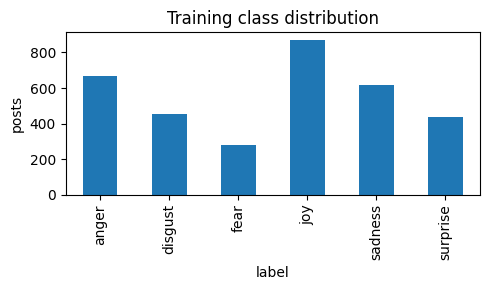

In [110]:
fig, ax = plt.subplots(figsize=(5, 3))
train_df["label"].value_counts().reindex(sorted(train_df["label"].unique())).plot(kind="bar", ax=ax, color="tab:blue")
print("counts", train_df["label"].value_counts().reindex(sorted(train_df["label"].unique())).to_dict()) 
ax.set_title("Training class distribution"); ax.set_ylabel("posts")
plt.tight_layout()
plt.savefig("pics/label_dist.png", dpi=150)
plt.show()

## 2. Feature Engineering Steps

In [123]:
### Add the code related to the feature engineering steps in cells inside this section
from transformers import AutoTokenizer

MODEL_NAME = "SamLowe/roberta-base-go_emotions"

labels = sorted(train_df["label"].unique())
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
lens = [len(tokenizer(t)["input_ids"]) for t in train_df["text"]]
print(pd.Series(lens).describe(percentiles=[.9, .95, .99]))
print("Truncated by max_length=128:", (pd.Series(lens) > 128).sum(), "posts")
print("Tokenize example '@user 😂 sooo happyyy':", tokenizer.tokenize("@user 😂 sooo happyyy"))
print("Tokenize example 2 '@<username> @<username> @<username> 😂😂😂😂😂. You are scared and cursed.':", tokenizer.tokenize("@<username> @<username> @<username> 😂😂😂😂😂. You are scared and cursed."))

count    3326.000000
mean       23.205652
std        30.253850
min         4.000000
50%        18.000000
90%        34.000000
95%        44.000000
99%       112.500000
max       511.000000
dtype: float64
Truncated by max_length=128: 27 posts
Tokenize example '@user 😂 sooo happyyy': ['@', 'user', 'ĠðŁĺ', 'Ĥ', 'Ġso', 'oo', 'Ġhappy', 'yy']
Tokenize example 2 '@<username> @<username> @<username> 😂😂😂😂😂. You are scared and cursed.': ['@', '<', 'username', '>', 'Ġ@', '<', 'username', '>', 'Ġ@', '<', 'username', '>', 'ĠðŁĺ', 'Ĥ', 'ðŁĺ', 'Ĥ', 'ðŁĺ', 'Ĥ', 'ðŁĺ', 'Ĥ', 'ðŁĺ', 'Ĥ', '.', 'ĠYou', 'Ġare', 'Ġscared', 'Ġand', 'Ġcursed', '.']


## 3. Model Implementation Steps

In [112]:
### Add the code related to the model implementation steps in cells inside this section
import numpy as np
import torch
from scipy.special import softmax
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding
from datasets import Dataset

def compute_metrics(p):
    return {"macro_f1": f1_score(p.label_ids, p.predictions.argmax(-1), average="macro")}

def run_5fold(model_name, save_prefix, lr=2e-5, epochs=4, use_fp16=True):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    def tok(batch):
        return tokenizer(batch["text"], truncation=True, max_length=128)
    
    test_ds = Dataset.from_dict({"text": test_df["text"].tolist()}).map(tok, batched=True)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    oof_probs = np.zeros((len(train_df), len(labels)))
    test_probs = np.zeros((len(test_df), len(labels)))
    y_all = train_df["label"].map(label2id).values

    for fold, (tr_idx, va_idx) in enumerate(skf.split(train_df, y_all)):
        tr_ds = Dataset.from_dict({
            "text": train_df["text"].iloc[tr_idx].tolist(),
            "label": y_all[tr_idx].tolist()
        }).map(tok, batched=True)
        va_ds = Dataset.from_dict({
            "text": train_df["text"].iloc[va_idx].tolist(),
            "label": y_all[va_idx].tolist()
        }).map(tok, batched=True)

        model = AutoModelForSequenceClassification.from_pretrained(
            model_name, num_labels=len(labels), id2label=id2label, label2id=label2id,
            ignore_mismatched_sizes=True, problem_type="single_label_classification"
        )
        warmup = int(0.1 * (len(tr_idx) // 16 + 1) * epochs)
        args = TrainingArguments(
            output_dir=f"outputs/{save_prefix}_f{fold}",
            eval_strategy="epoch", save_strategy="epoch",
            learning_rate=lr, warmup_steps=warmup, weight_decay=0.01,
            lr_scheduler_type="cosine", label_smoothing_factor=0.05,
            per_device_train_batch_size=16, per_device_eval_batch_size=64,
            num_train_epochs=epochs,
            load_best_model_at_end=True, metric_for_best_model="eval_loss",
            save_total_limit=1, fp16=use_fp16, report_to="none", seed=42 + fold
        )

        trainer = Trainer(
            model=model, args=args, train_dataset=tr_ds, eval_dataset=va_ds,
            data_collator=DataCollatorWithPadding(tokenizer),compute_metrics=compute_metrics
        )
        trainer.train()

        va_logits = trainer.predict(va_ds).predictions
        oof_probs[va_idx] = softmax(va_logits, axis=1)

        te_logits = trainer.predict(test_ds).predictions
        test_probs += softmax(te_logits, axis=1) / 5.0

    oof_f1 = f1_score(y_all, oof_probs.argmax(1), average="macro")
    print(f"[{save_prefix}] 5-Fold OOF Macro F1: {oof_f1:.4f}")
    np.save(f"{save_prefix}_oof.npy", oof_probs)
    np.save(f"{save_prefix}_test.npy", test_probs)
    return oof_probs, test_probs

In [113]:
#Training
oof_goemo, test_goemo = run_5fold("SamLowe/roberta-base-go_emotions", "goemo", lr=1e-5, epochs=4, use_fp16=True)
oof_rob,   test_rob   = run_5fold("roberta-large", "roberta_large", lr=1e-5, epochs=5, use_fp16=True)

Map: 100%|██████████| 666/666 [00:00<00:00, 50045.80 examples/s]
[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `28`.
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 6087.61it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: SamLowe/roberta-base-go_emotions
Key                        | Status   |                                                                                        
---------------------------+----------+----------------------------------------------------------------------------------------
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([28, 768]) vs model:torch.Size([6, 768])
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([28]) vs model:torch.Size([6])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[RANK 0] Detected kernel version 5.4.0, which is be

Epoch,Training Loss,Validation Loss,Macro F1
1,No log,1.138489,0.616628
2,No log,1.040326,0.644284
3,1.204962,1.036600,0.657358
4,1.204962,1.044846,0.656348


Writing model shards: 100%|██████████| 1/1 [00:05<00:00,  5.31s/it]


Map: 100%|██████████| 665/665 [00:00<00:00, 46813.79 examples/s]
[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `28`.
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 6706.56it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: SamLowe/roberta-base-go_emotions
Key                        | Status   |                                                                                        
---------------------------+----------+----------------------------------------------------------------------------------------
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([28, 768]) vs model:torch.Size([6, 768])
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([28]) vs model:torch.Size([6])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[RANK 0] Detected kernel version 5.4.0, which is be

Epoch,Training Loss,Validation Loss,Macro F1
1,No log,1.169798,0.610345
2,No log,1.117777,0.620878
3,1.168167,1.126269,0.621359
4,1.168167,1.128137,0.621507


Writing model shards: 100%|██████████| 1/1 [00:05<00:00,  5.27s/it]


... (22 outputs left out)

Loading weights: 100%|██████████| 389/389 [00:00<00:00, 5801.58it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-large
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[RANK 0] Detected kernel version 5.4.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is

Epoch,Training Loss,Validation Loss,Macro F1
1,No log,1.504507,0.344069
2,No log,1.246614,0.530974
3,1.339059,1.274860,0.551436
4,1.339059,1.373421,0.558479
5,1.339059,1.373682,0.566391


Writing model shards: 100%|██████████| 1/1 [00:16<00:00, 16.69s/it]


[roberta_large] 5-Fold OOF Macro F1: 0.5863


In [114]:
import numpy as np, pandas as pd
from scipy.optimize import minimize
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

oof_goemo, test_goemo = np.load("goemo_oof.npy"), np.load("goemo_test.npy")
oof_rob,   test_rob   = np.load("roberta_large_oof.npy"), np.load("roberta_large_test.npy")
y_all = train_df["label"].map(label2id).values

best_alpha, best_f1 = 0.5, 0
for alpha in np.linspace(0.3, 0.8, 51):
    blend = alpha * oof_goemo + (1 - alpha) * oof_rob
    score = f1_score(y_all, blend.argmax(1), average="macro")
    if score > best_f1:
        best_f1, best_alpha = score, alpha

print(f"Best alpha={best_alpha:.2f} | Raw Blend OOF Macro F1: {best_f1:.4f}")
oof_ens  = best_alpha * oof_goemo  + (1 - best_alpha) * oof_rob
test_ens = best_alpha * test_goemo + (1 - best_alpha) * test_rob

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
nested_preds = np.zeros(len(y_all), dtype=int)
weights_list = []

for tr_idx, va_idx in skf.split(oof_ens, y_all):
    def loss_fn(w):
        return -f1_score(y_all[tr_idx], (oof_ens[tr_idx] * w).argmax(1), average="macro")
    res = minimize(loss_fn, np.ones(len(labels)), method="Nelder-Mead")
    weights_list.append(res.x)
    nested_preds[va_idx] = (oof_ens[va_idx] * res.x).argmax(1)

print(f"Post-processed (Nested CV) OOF Macro F1: {f1_score(y_all, nested_preds, average='macro'):.4f}")

avg_w = np.mean(weights_list, axis=0)
print("Avg class weights:", dict(zip(labels, np.round(avg_w, 3))))

test_ens = best_alpha * test_goemo + (1-best_alpha) * test_rob
pd.DataFrame({
    "id": test_df["post_id"].values,
    "label": [id2label[i] for i in test_ens.argmax(1)]
}).to_csv("submission_ens.csv", index=False)

Best alpha=0.62 | Raw Blend OOF Macro F1: 0.6287
Post-processed (Nested CV) OOF Macro F1: 0.6305
Avg class weights: {'anger': np.float64(1.0), 'disgust': np.float64(1.078), 'fear': np.float64(0.974), 'joy': np.float64(1.007), 'sadness': np.float64(1.039), 'surprise': np.float64(0.972)}


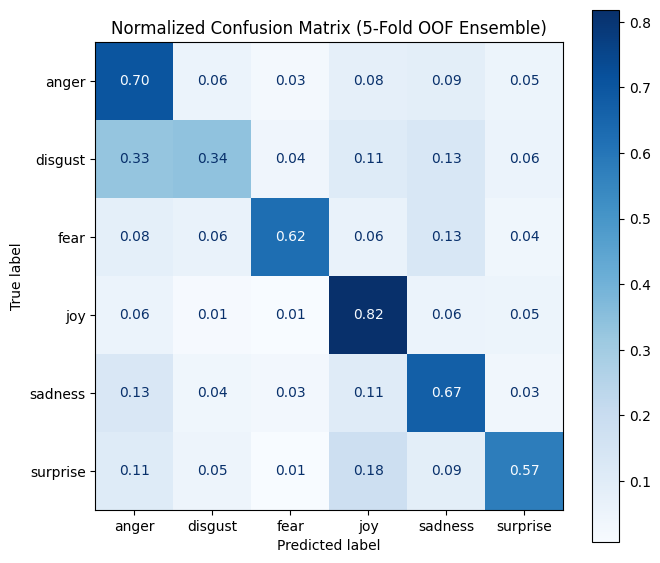

In [115]:
#PLot
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_all,
    oof_ens.argmax(1),
    display_labels=labels,
    normalize="true",
    values_format=".2f", 
    cmap="Blues",
    ax=ax
)
plt.title("Normalized Confusion Matrix (5-Fold OOF Ensemble)")
plt.tight_layout()

plt.savefig("./pics/confusion_matrix.png", dpi=150)
plt.show()